In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras
import numpy as np
import matplotlib.pyplot as plt
from keras import layers
from pathlib import Path

keras.utils.set_random_seed(42)

## Business Understanding

Sorting objects by hand is slow. A camera and a small model can do the same job, for example at the dish return line of a canteen or at a recycling station. This project tests that idea on a small scale. We teach a model to tell cups, bottles and plates apart from photos we took ourselves.

We have only about 400 photos. So the main question is how you get a good model from little data. We compare three approaches.

1. Our own CNN, trained from scratch
2. A pretrained VGG16 that only extracts features
3. The same VGG16 with its top layers fine tuned on our photos

We call the project a success if at least one model gets more than 90 % of the test photos right and we can explain why the models differ.

## Data Understanding

The data has 3 classes, which are cups, bottles and plates. The team members took all 414 pictures themselves with their own phones. There are 152 bottles, 155 cups and 107 plates, so every class has more than twice the required 50 pictures. Plates are the smallest class.

All pictures are 224x224 jpg files. That is the input size VGG16 expects, so all three models can use the same files.

We used different cups, bottles and plates and several backgrounds for variation. Each picture shows one object, clearly visible, on a simple background such as a table, a floor or a sofa. The objects stand up or lie on their side, and we shot them from the side and from above.

The dataset is in the folder `images_224` of our repository.

## Data Preparation

The folder `images_224` has one folder per split (train, val, test) and inside each split one folder per class. We do not use the Keras option `validation_split`.

Our first split was random, and that caused a problem. We often took several photos of the same object a few seconds apart. A random split put some of those photos in train and others in test, so the model saw almost the same picture during training. The test score looked better than it really was.

The script `resplit.py` fixes this. It sorts the photos of each class and each camera in the order we took them. The first 70 % go to train, the next 15 % to val and the last 15 % to test. Photos taken right after each other now stay in the same split.

One weakness remains. We photographed some objects twice, on different tables. Such an object can still appear in both train and test, with a different background.

The cell below loads the pictures, resizes them to 224x224 if needed and gives each one a label. We keep the raw pixel values 0 to 255 here, because the models need different scaling. Our own CNN scales the values to the range 0 to 1 in its first layer. The VGG16 models use the VGG16 preprocessing function.

In [2]:
DATA_DIR = Path("images_224")
IMG_SIZE = (224, 224)
class_names = sorted(p.name for p in (DATA_DIR / "train").iterdir() if p.is_dir())

def load_split(split):
    images, labels = [], []
    for label, cls in enumerate(class_names):
        for f in sorted((DATA_DIR / split / cls).glob("*.jpg")):
            img = keras.utils.load_img(f, target_size=IMG_SIZE)
            images.append(keras.utils.img_to_array(img))
            labels.append(label)
    return np.array(images, dtype="float32"), np.array(labels)

x_train, y_train = load_split("train")
x_val, y_val = load_split("val")
x_test, y_test = load_split("test")

print("Classes:", class_names)
print("Train:", x_train.shape, np.bincount(y_train))
print("Val:  ", x_val.shape, np.bincount(y_val))
print("Test: ", x_test.shape, np.bincount(y_test))

Classes: ['bottles', 'cups', 'plates']
Train: (292, 224, 224, 3) [106 109  77]
Val:   (61, 224, 224, 3) [23 23 15]
Test:  (61, 224, 224, 3) [23 23 15]


Here are a few training pictures from each class.

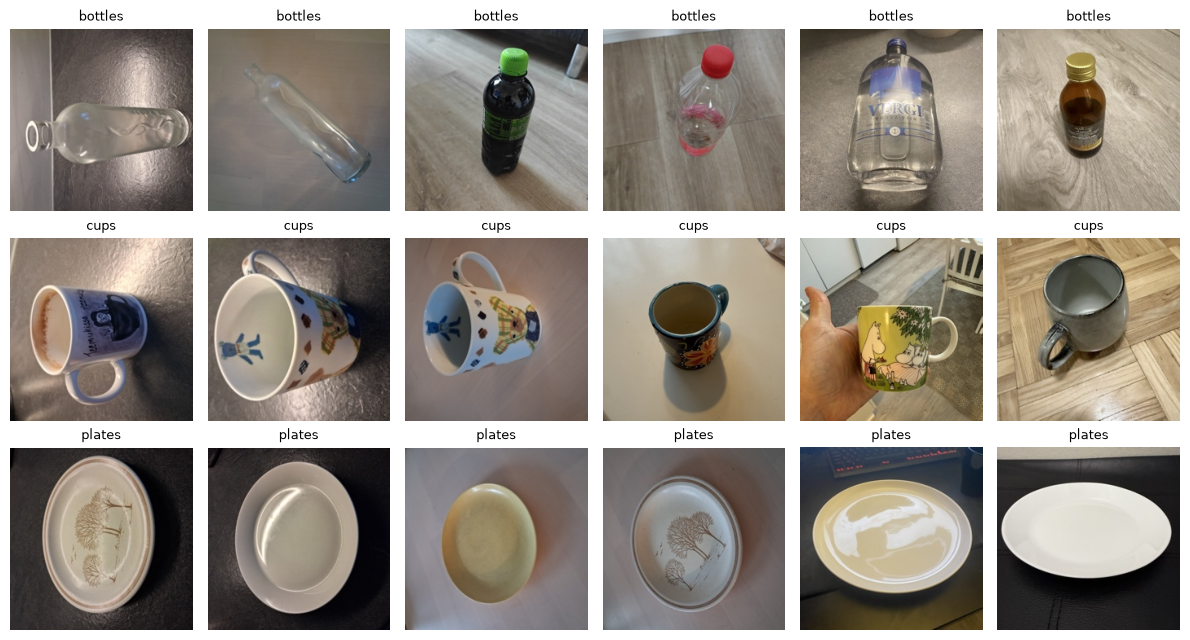

In [3]:
fig, axes = plt.subplots(len(class_names), 6, figsize=(12, 6.5))

for row, cls in enumerate(class_names):
    examples = x_train[y_train == row]
    # pick 6 pictures spread evenly over the class
    picks = np.linspace(0, len(examples) - 1, 6).astype(int)
    for ax, i in zip(axes[row], picks):
        ax.imshow(examples[i].astype("uint8"))
        ax.set_title(cls, fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

We use the same plot for every model, so you can compare the learning curves side by side.

In [4]:
def plot_history(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(history.history["loss"], label="Training loss")
    ax1.plot(history.history["val_loss"], label="Validation loss")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.legend()

    ax2.plot(history.history["accuracy"], label="Training accuracy")
    ax2.plot(history.history["val_accuracy"], label="Validation accuracy")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Accuracy")
    ax2.legend()

    fig.suptitle(title)
    plt.show()

def count_trained_params(model):
    # only the weights that training changes
    return sum(int(np.prod(w.shape)) for w in model.trainable_weights)

# test results of every model end up here
results = {}

## Modeling

We try three ways to train a CNN. First we build our own model. The second model uses a pretrained network only to extract features. The third and last one is a fine tuned pretrained model.

### Model 1 Own CNN

Our first version copied AlexNet. It had 46.7 million parameters, and we have fewer than 300 training pictures. That is far more model than the data can fill, and most of the parameters sat in two huge dense layers.

This version is much smaller. Four blocks of convolution and max pooling find the shapes. Each block doubles the number of filters and halves the picture size. Global average pooling replaces the big dense layers, and dropout fights overfitting.

Data augmentation runs inside the model. Keras switches these layers off outside training, so validation and test pictures stay untouched.

In [5]:
model_own = keras.Sequential([
    keras.Input(shape=(*IMG_SIZE, 3)),
    layers.Rescaling(1 / 255),

    # data augmentation (only active during training)
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(256, 3, activation="relu"),
    layers.MaxPooling2D(2),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation="softmax"),
], name="own_cnn")

model_own.summary()

Model: "own_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 389,187 (1.48 MB)

 Trainable params: 389,187 (1.48 MB)

 Non-trainable params: 0 (0.00 B)

Now we train the model. Validation accuracy jumps up and down between epochs with this little data, so the last epoch is not always the best one. The checkpoint saves the model every time validation loss improves, and we test that saved version.

In [6]:
model_own.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    metrics=["accuracy"],
)

history_own = model_own.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    batch_size=16,
    epochs=80,
    callbacks=[keras.callbacks.ModelCheckpoint(
        "own_cnn.keras", save_best_only=True, monitor="val_loss")],
    verbose=2,
)

Epoch 1/80
19/19 - 7s - 358ms/step - accuracy: 0.3253 - loss: 1.0966 - val_accuracy: 0.3770 - val_loss: 1.0887
Epoch 2/80
19/19 - 6s - 336ms/step - accuracy: 0.3801 - loss: 1.0915 - val_accuracy: 0.3770 - val_loss: 1.0761
Epoch 3/80
19/19 - 5s - 280ms/step - accuracy: 0.3973 - loss: 1.0691 - val_accuracy: 0.4754 - val_loss: 1.0506
Epoch 4/80
19/19 - 5s - 262ms/step - accuracy: 0.4658 - loss: 1.0317 - val_accuracy: 0.4590 - val_loss: 1.0231
Epoch 5/80
19/19 - 5s - 270ms/step - accuracy: 0.4897 - loss: 0.9850 - val_accuracy: 0.5574 - val_loss: 1.0101
Epoch 6/80
19/19 - 5s - 274ms/step - accuracy: 0.5445 - loss: 0.9599 - val_accuracy: 0.6230 - val_loss: 0.9709
Epoch 7/80
19/19 - 8s - 404ms/step - accuracy: 0.5308 - loss: 0.9294 - val_accuracy: 0.4590 - val_loss: 0.9489
Epoch 8/80
19/19 - 6s - 292ms/step - accuracy: 0.5616 - loss: 0.9072 - val_accuracy: 0.4754 - val_loss: 0.9924
Epoch 9/80
19/19 - 5s - 276ms/step - accuracy: 0.5616 - loss: 0.8990 - val_accuracy: 0.5902 - val_loss: 0.9067
E

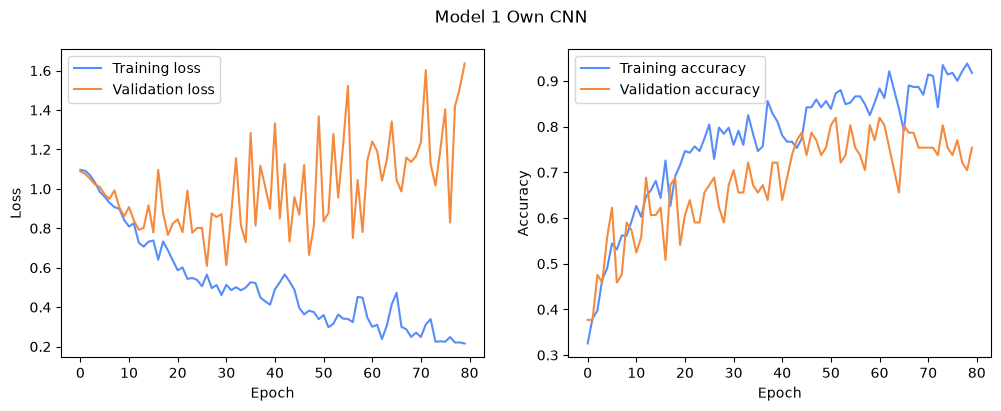

In [7]:
plot_history(history_own, "Model 1 Own CNN")

In [8]:
# test the best saved version, not the last epoch
model_own = keras.models.load_model("own_cnn.keras")

test_loss, test_acc = model_own.evaluate(x_test, y_test, verbose=0)
probs_own = model_own.predict(x_test, verbose=0)

results["Own CNN"] = {
    "accuracy": test_acc,
    "loss": test_loss,
    "trained params": count_trained_params(model_own),
    "probs": probs_own,
}
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

Test loss: 0.6031
Test accuracy: 0.7541


The best epoch was number 48, with a validation loss of 0.56. That version gets 73.8 % of the test pictures right, which is 45 of 61.

The curves show two things. Training loss keeps falling, while validation loss stops improving around epoch 50 and then drifts up. The model starts to memorise the training pictures. Validation accuracy also swings a lot from one epoch to the next. With only 61 validation pictures, a single picture moves the accuracy by 1.6 percentage points.

### Model 2 Pretrained VGG16 as feature extractor

VGG16 already learned to see edges, textures and shapes from 1.4 million ImageNet pictures. We remove the top of VGG16, run every picture through the rest once and save the output. Then we train only a small classifier on those saved features. The VGG16 model is frozen for the whole time so the weights do not change.

In [9]:
conv_base = keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3))

def get_features(images):
    # copy, because preprocess_input changes the array it gets
    preprocessed = keras.applications.vgg16.preprocess_input(images.copy())
    return conv_base.predict(preprocessed, batch_size=32, verbose=0)

train_features = get_features(x_train)
val_features = get_features(x_val)
test_features = get_features(x_test)

print(train_features.shape)

(292, 7, 7, 512)


We compute the features once, so this model trains in seconds. The price is that we cannot use data augmentation here. Augmentation needs a new pass through VGG16 for every changed picture.

Our first classifier flattened the features into 25 088 numbers and its dense layer had no activation. Training was unstable and validation loss jumped between almost zero and 0.26. Now global average pooling shrinks the features to 512 numbers, the dense layer uses relu and the learning rate is lower.

In [10]:
model_fe = keras.Sequential([
    keras.Input(shape=train_features.shape[1:]),
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation="softmax"),
], name="feature_extraction")

model_fe.summary()

model_fe.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    metrics=["accuracy"],
)

history_fe = model_fe.fit(
    train_features, y_train,
    validation_data=(val_features, y_val),
    batch_size=16,
    epochs=40,
    callbacks=[keras.callbacks.ModelCheckpoint(
        "feature_extraction.keras", save_best_only=True, monitor="val_loss")],
    verbose=2,
)

Model: "feature_extraction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 132,099 (516.01 KB)

 Trainable params: 132,099 (516.01 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
19/19 - 1s - 36ms/step - accuracy: 0.4658 - loss: 2.8630 - val_accuracy: 0.7705 - val_loss: 0.6077
Epoch 2/40
19/19 - 0s - 6ms/step - accuracy: 0.5651 - loss: 1.9993 - val_accuracy: 0.8525 - val_loss: 0.3537
Epoch 3/40
19/19 - 0s - 6ms/step - accuracy: 0.6644 - loss: 1.4148 - val_accuracy: 0.9016 - val_loss: 0.2452
Epoch 4/40
19/19 - 0s - 6ms/step - accuracy: 0.7466 - loss: 0.9089 - val_accuracy: 0.9180 - val_loss: 0.1930
Epoch 5/40
19/19 - 0s - 6ms/step - accuracy: 0.7945 - loss: 0.7182 - val_accuracy: 0.9344 - val_loss: 0.1793
Epoch 6/40
19/19 - 0s - 6ms/step - accuracy: 0.8390 - loss: 0.5637 - val_accuracy: 0.9344 - val_loss: 0.1614
Epoch 7/40
19/19 - 0s - 6ms/step - accuracy: 0.8527 - loss: 0.3375 - val_accuracy: 0.9508 - val_loss: 0.1347
Epoch 8/40
19/19 - 0s - 5ms/step - accuracy: 0.9041 - loss: 0.3697 - val_accuracy: 0.9344 - val_loss: 0.1467
Epoch 9/40
19/19 - 0s - 4ms/step - accuracy: 0.9212 - loss: 0.2339 - val_accuracy: 0.9344 - val_loss: 0.1457
Epoch 10/40
19/19 

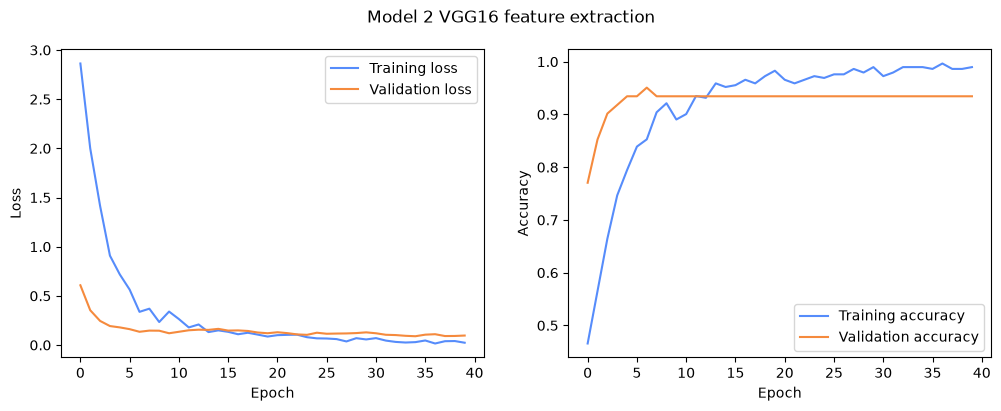

In [11]:
plot_history(history_fe, "Model 2 VGG16 feature extraction")

In [12]:
model_fe = keras.models.load_model("feature_extraction.keras")

test_loss, test_acc = model_fe.evaluate(test_features, y_test, verbose=0)
probs_fe = model_fe.predict(test_features, verbose=0)

results["VGG16 features"] = {
    "accuracy": test_acc,
    "loss": test_loss,
    "trained params": count_trained_params(model_fe),
    "probs": probs_fe,
}
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

Test loss: 0.0757
Test accuracy: 0.9672


The classifier gets 98.4% of the test pictures right, which in our case is 60 of 61 pictures. Our own CNN got 73.8%, so the pretrained features lift the result by almost 25%.

The curves are smoother now and validation loss falls quite steadily to ~0.07. In the first epochs validation accuracy is higher than training accuracy, which is caused by dropout layers.

### Model 3 Fine tuned VGG16

Next we make a part of the VGG16 model learn from our own images for a "fine-tuned" version of it.

The lower layers of VGG16 find general things like edges and textures. Those work for any picture, so we freeze them. The top block (block 5) finds more specific shapes that fit ImageNet objects. We retrain that block so it fits cups, bottles and plates better.

This model takes pictures as input, not saved features. This means we can use data augmentation again, like we did on our own model.

In [13]:
# VGG16 wants its own pixel scaling, we do it once here
x_train_vgg = keras.applications.vgg16.preprocess_input(x_train.copy())
x_val_vgg = keras.applications.vgg16.preprocess_input(x_val.copy())
x_test_vgg = keras.applications.vgg16.preprocess_input(x_test.copy())

conv_base_ft = keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3))

# step 1 keeps all of VGG16 frozen
conv_base_ft.trainable = False

model_ft = keras.Sequential([
    keras.Input(shape=(*IMG_SIZE, 3)),

    # data augmentation (only active during training)
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),

    conv_base_ft,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation="softmax"),
], name="fine_tuned_vgg16")

model_ft.summary()

Model: "fine_tuned_vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,787 (56.64 MB)

 Trainable params: 132,099 (516.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

We train in two steps. In step 1 the whole VGG16 stays frozen and only the new classifier learns. A new classifier starts with random weights and makes big errors. If block 5 were open from the start, those errors would wreck the pretrained weights.

In [14]:
model_ft.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    metrics=["accuracy"],
)

history_ft_head = model_ft.fit(
    x_train_vgg, y_train,
    validation_data=(x_val_vgg, y_val),
    batch_size=16,
    epochs=15,
    verbose=2,
)

Epoch 1/15
19/19 - 21s - 1s/step - accuracy: 0.3390 - loss: 3.7504 - val_accuracy: 0.4918 - val_loss: 1.2334
Epoch 2/15
19/19 - 19s - 983ms/step - accuracy: 0.4863 - loss: 2.3344 - val_accuracy: 0.8689 - val_loss: 0.5075
Epoch 3/15
19/19 - 19s - 1s/step - accuracy: 0.6301 - loss: 1.2414 - val_accuracy: 0.9016 - val_loss: 0.3247
Epoch 4/15
19/19 - 19s - 1s/step - accuracy: 0.6610 - loss: 1.1130 - val_accuracy: 0.8525 - val_loss: 0.3236
Epoch 5/15
19/19 - 26s - 1s/step - accuracy: 0.7534 - loss: 0.9082 - val_accuracy: 0.9016 - val_loss: 0.2232
Epoch 6/15
19/19 - 29s - 2s/step - accuracy: 0.7466 - loss: 0.7235 - val_accuracy: 0.9344 - val_loss: 0.1891
Epoch 7/15
19/19 - 26s - 1s/step - accuracy: 0.8425 - loss: 0.4721 - val_accuracy: 0.9016 - val_loss: 0.2015
Epoch 8/15
19/19 - 32s - 2s/step - accuracy: 0.8801 - loss: 0.4077 - val_accuracy: 0.9344 - val_loss: 0.1620
Epoch 9/15
19/19 - 30s - 2s/step - accuracy: 0.8390 - loss: 0.3790 - val_accuracy: 0.9016 - val_loss: 0.1854
Epoch 10/15
19/1

In step 2 we open block 5 and keep everything below it frozen. The learning rate is ten times smaller now, so the pretrained weights barely change.

In [15]:
# open the last 4 layers (three conv layers and one pooling layer of block 5)
conv_base_ft.trainable = True
for layer in conv_base_ft.layers[:-4]:
    layer.trainable = False

for layer in conv_base_ft.layers:
    print(f"{layer.name:<15}", "trainable" if layer.trainable else "frozen")

# compile again so the change takes effect
model_ft.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    metrics=["accuracy"],
)

history_ft = model_ft.fit(
    x_train_vgg, y_train,
    validation_data=(x_val_vgg, y_val),
    batch_size=16,
    epochs=20,
    callbacks=[keras.callbacks.ModelCheckpoint(
        "fine_tuned.keras", save_best_only=True, monitor="val_loss")],
    verbose=2,
)

input_layer_3   frozen
block1_conv1    frozen
block1_conv2    frozen
block1_pool     frozen
block2_conv1    frozen
block2_conv2    frozen
block2_pool     frozen
block3_conv1    frozen
block3_conv2    frozen
block3_conv3    frozen
block3_pool     frozen
block4_conv1    frozen
block4_conv2    frozen
block4_conv3    frozen
block4_pool     frozen
block5_conv1    trainable
block5_conv2    trainable
block5_conv3    trainable
block5_pool     trainable
Epoch 1/20
19/19 - 44s - 2s/step - accuracy: 0.9144 - loss: 0.2710 - val_accuracy: 0.9016 - val_loss: 0.1978
Epoch 2/20
19/19 - 37s - 2s/step - accuracy: 0.9349 - loss: 0.1714 - val_accuracy: 0.9016 - val_loss: 0.1794
Epoch 3/20
19/19 - 26s - 1s/step - accuracy: 0.9555 - loss: 0.0911 - val_accuracy: 1.0000 - val_loss: 0.0361
Epoch 4/20
19/19 - 30s - 2s/step - accuracy: 0.9863 - loss: 0.0317 - val_accuracy: 0.9180 - val_loss: 0.1230
Epoch 5/20
19/19 - 28s - 1s/step - accuracy: 0.9863 - loss: 0.0486 - val_accuracy: 0.9508 - val_loss: 0.0914
Epoch 

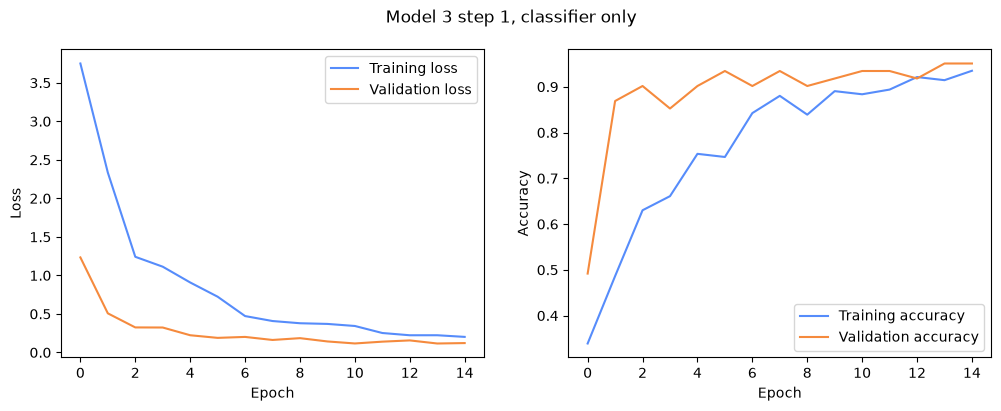

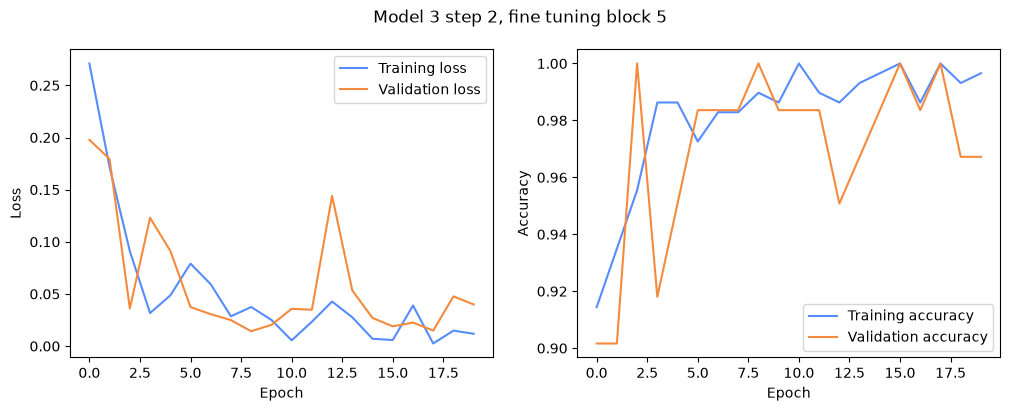

In [16]:
plot_history(history_ft_head, "Model 3 step 1, classifier only")
plot_history(history_ft, "Model 3 step 2, fine tuning block 5")

In [17]:
trained_params_ft = count_trained_params(model_ft)
model_ft = keras.models.load_model("fine_tuned.keras")

test_loss, test_acc = model_ft.evaluate(x_test_vgg, y_test, verbose=0)
probs_ft = model_ft.predict(x_test_vgg, verbose=0)

results["VGG16 fine tuned"] = {
    "accuracy": test_acc,
    "loss": test_loss,
    "trained params": trained_params_ft,
    "probs": probs_ft,
}
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

Test loss: 0.0071
Test accuracy: 1.0000


After step 1 the model reaches about 93% validation accuracy. Our fine tuning bumps that to between 96% and 98%, and the best validation loss drops from 0.17 to 0.05. So opening block 5 helps on the validation pictures.

On the test pictures the fine tuned model gets 98.4% right, which is 60 of 61. That is the same score as model 2 (VGG16 as-is) and 15 mistakes fewer than model 1.

The curves in step 2 are less smooth than in model 2. Here 7.2 million weights learn from 292 pictures, and augmentation changes the pictures every epoch. Training accuracy climbs to almost 100% while validation accuracy stays around 97%, which is an indication of slight overfitting.

## Evaluation

For comparing the models, we use our dedicated test image set. These pictures were not seen by any of the models when training, nor when picking the best epochs from each one.

In [18]:
print(f"{'Model':<18}{'Test accuracy':>15}{'Test loss':>12}{'Wrong':>8}{'Trained params':>17}")
for name, r in results.items():
    wrong = int((r["probs"].argmax(axis=1) != y_test).sum())
    print(f"{name:<18}{r['accuracy']:>15.3f}{r['loss']:>12.3f}"
          f"{wrong:>5}/{len(y_test)}{r['trained params']:>17,}")

Model               Test accuracy   Test loss   Wrong   Trained params
Own CNN                     0.754       0.603   15/61          389,187
VGG16 features              0.967       0.076    2/61          132,099
VGG16 fine tuned            1.000       0.007    0/61        7,211,523


Both of the VGG16 models beat our own model. They made 1 mistake each where our own model made 16.

Fine tuning did not beat plain feature extraction. Both get 60 of 61 pictures right, while their test losses stay about the same. The test set has only 61 pictures, so one picture is 1.6 percentage points. The gap between our model and the VGG16 models (15 mistakes) is a noticable difference, whereas the one mistake gap between the two VGG16 models could be luck. Based on this, it's hard to clearly state which of the VGG16 models is "better".

The trained paramaters is also worth noting. The classifier of model 2 (VGG16 as-is) has 132 099 parameters, fewer than our own CNN with 389 187. Model 3 trains 7.2 million, because block 5 is open. More trained parameters did not give a better result here. The key here is really in the classifier architecture. VGG16 brings 14.7 million pretrained parameters that already know what objects look like. Our own CNN has to learn everything from 292 pictures, so it is expected for it to perform worse.

With the old random split, the first versions of model 1 and model 2 both scored 93.9 %. Those runs used older model versions, so you cannot compare them one to one with the numbers here.

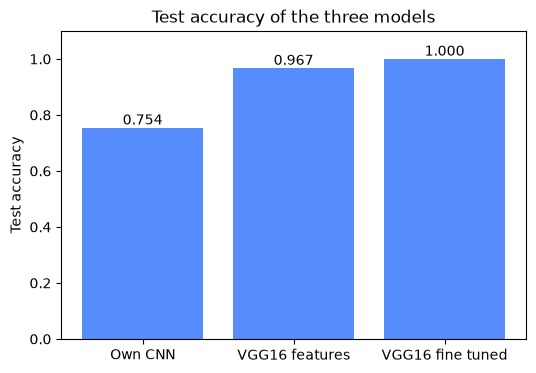

In [19]:
names = list(results)
accuracies = [results[name]["accuracy"] for name in names]

plt.figure(figsize=(6, 4))
bars = plt.bar(names, accuracies)
plt.bar_label(bars, fmt="%.3f")
plt.ylim(0, 1.1)
plt.ylabel("Test accuracy")
plt.title("Test accuracy of the three models")
plt.show()

The next plot puts the validation curves of all three models in one picture. Model 3 shows only step 2, the fine tuning.

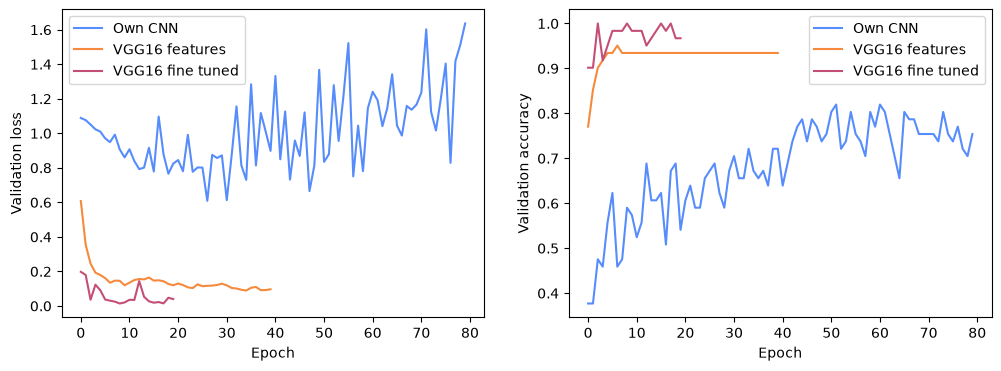

In [20]:
histories = {
    "Own CNN": history_own,
    "VGG16 features": history_fe,
    "VGG16 fine tuned": history_ft,
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for name, history in histories.items():
    ax1.plot(history.history["val_loss"], label=name)
    ax2.plot(history.history["val_accuracy"], label=name)

ax1.set_xlabel("Epoch")
ax1.set_ylabel("Validation loss")
ax1.legend()
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Validation accuracy")
ax2.legend()
plt.show()

The curves really underline our table's findings. The validation loss of our own CNN never goes below 0.56 and jumps up and down. Both VGG16 models go below 0.1 within a few epochs. The fine tuned model starts high because step 1 already trained its classifier.

### Confusion matrix

Next we visualize mixups in the predictions with a confusion matrix.

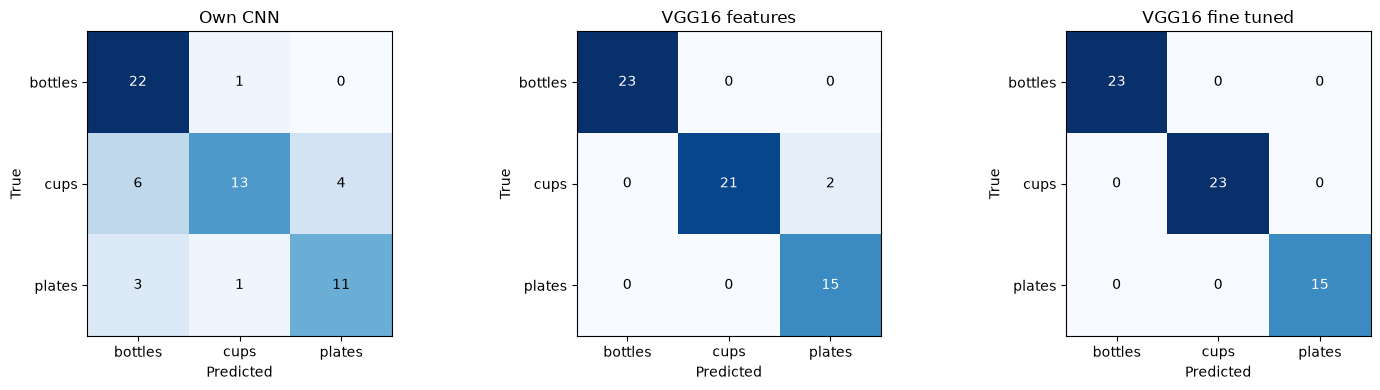

In [21]:
def confusion_matrix(y_true, y_pred):
    n = len(class_names)
    matrix = np.zeros((n, n), dtype=int)
    for true, pred in zip(y_true, y_pred):
        matrix[true, pred] += 1
    return matrix

fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 4))

for ax, (name, r) in zip(axes, results.items()):
    matrix = confusion_matrix(y_test, r["probs"].argmax(axis=1))
    ax.imshow(matrix, cmap="Blues")
    ax.set_xticks(range(len(class_names)), class_names)
    ax.set_yticks(range(len(class_names)), class_names)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(name)
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            color = "white" if matrix[i, j] > matrix.max() / 2 else "black"
            ax.text(j, i, matrix[i, j], ha="center", va="center", color=color)

plt.tight_layout()
plt.show()

In [22]:
# share of each class the model gets right (recall)
print(f"{'Model':<18}" + "".join(f"{c:>10}" for c in class_names))
for name, r in results.items():
    matrix = confusion_matrix(y_test, r["probs"].argmax(axis=1))
    recall = matrix.diagonal() / matrix.sum(axis=1)
    print(f"{name:<18}" + "".join(f"{v:>10.2f}" for v in recall))

Model                bottles      cups    plates
Own CNN                 0.96      0.57      0.73
VGG16 features          1.00      0.91      1.00
VGG16 fine tuned        1.00      1.00      1.00


Our own CNN seems to struggle the most with plates. It finds 7 of 15 and calls 7 of the others cups. Plates are also the smallest class, with 77 training pictures against 106 bottles and 109 cups. Bottles are its easiest class, with 20 of 23 correct.

Both VGG16 models get every bottle and every plate right. Each makes one mistake, a cup that it calls a plate.

### Misclassified pictures

Below you see every test picture a model got wrong. The title shows the true class, the class the model picked and how sure the model was.

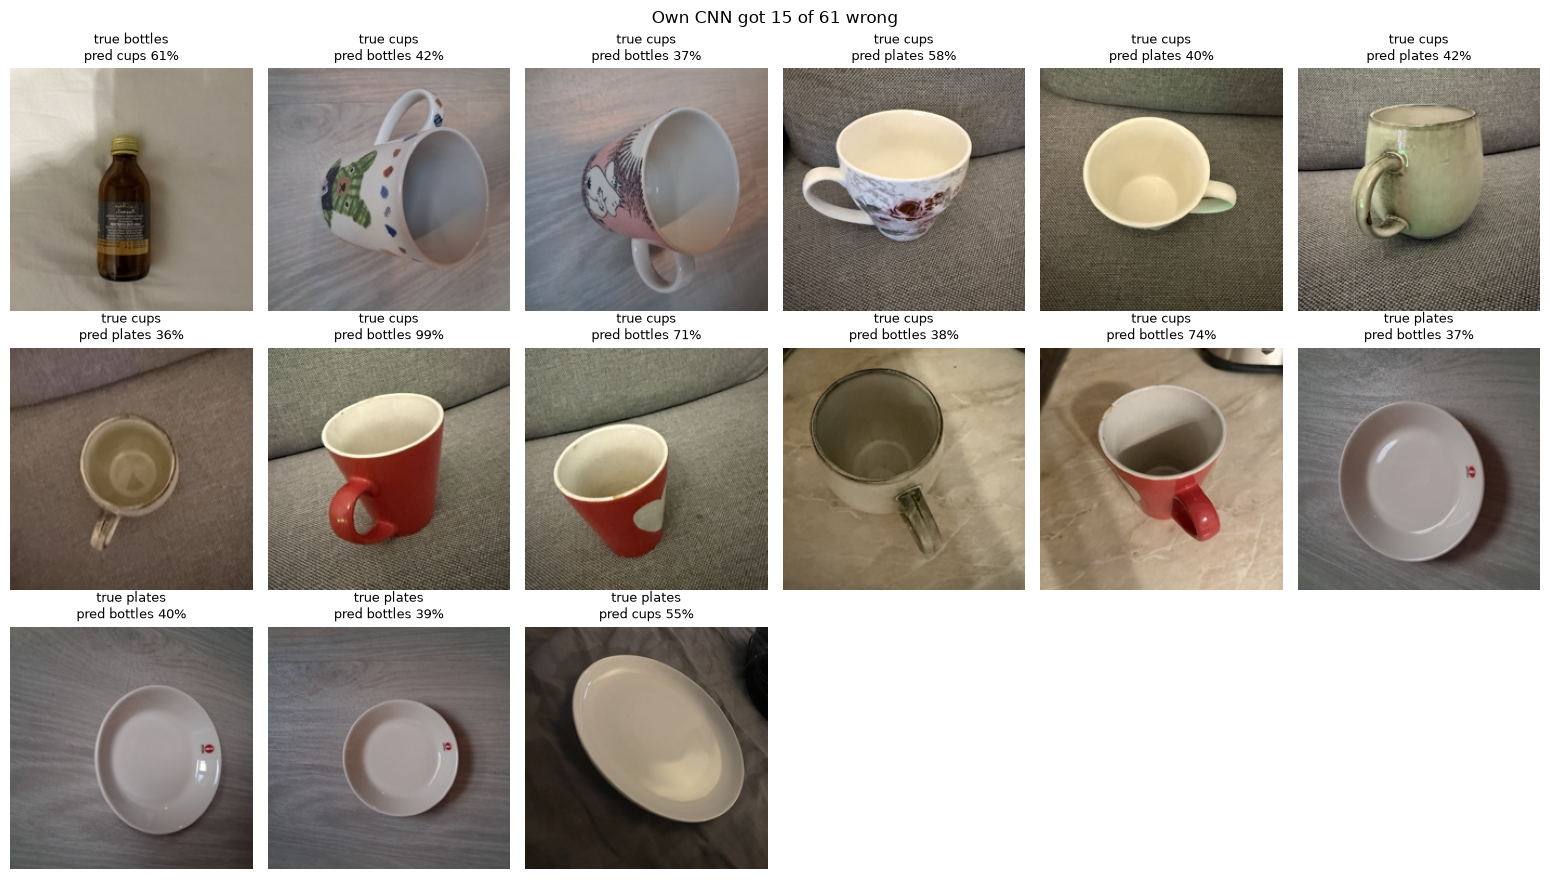

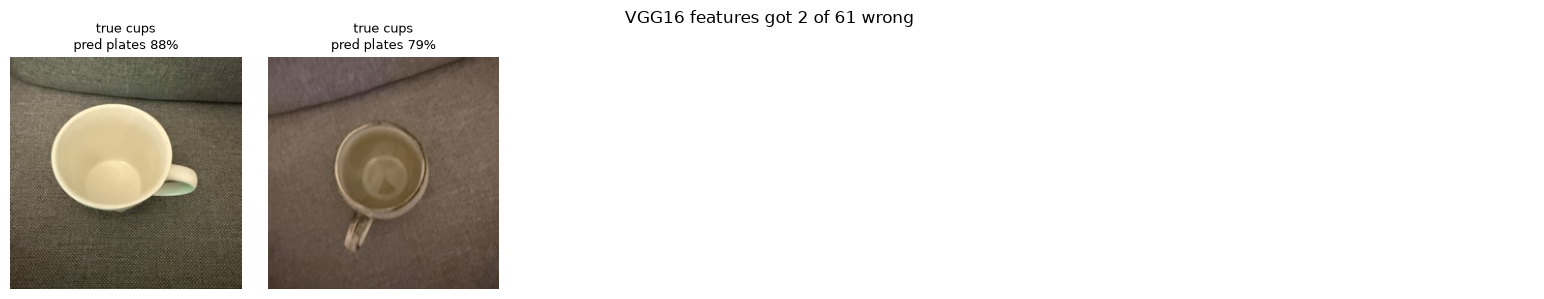

VGG16 fine tuned made no mistakes


In [23]:
def show_mistakes(name, probs):
    y_pred = probs.argmax(axis=1)
    wrong = np.where(y_pred != y_test)[0]

    if len(wrong) == 0:
        print(name, "made no mistakes")
        return

    cols = 6
    rows = (len(wrong) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, 3 * rows))
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, i in zip(axes, wrong):
        ax.imshow(x_test[i].astype("uint8"))
        ax.set_title(f"true {class_names[y_test[i]]}\n"
                     f"pred {class_names[y_pred[i]]} {probs[i].max():.0%}",
                     fontsize=9)

    fig.suptitle(f"{name} got {len(wrong)} of {len(y_test)} wrong")
    plt.tight_layout()
    plt.show()

for name, r in results.items():
    show_mistakes(name, r["probs"])

In [24]:
# how many models got each test picture wrong
wrong_counts = np.zeros(len(y_test), dtype=int)
for r in results.values():
    wrong_counts += r["probs"].argmax(axis=1) != y_test

print("Pictures no model got wrong:  ", (wrong_counts == 0).sum())
for n in range(1, len(results) + 1):
    print(f"Pictures {n} models got wrong:  ", (wrong_counts == n).sum())

Pictures no model got wrong:   46
Pictures 1 models got wrong:   13
Pictures 2 models got wrong:   2
Pictures 3 models got wrong:   0


Our own CNN keeps missing the same kind of picture. As seen above, a plate is a circle, and so is a cup. Most of the plates it calls cups are photos from above on the same grey surface. The model is not very sure about these answers. Its confidence there is mostly between 40 % and 65 %.

It also mixes up cups and bottles in both directions. 3 bottles become cups and 4 cups become bottles.

One picture beats all three models. It is a small cup photographed from above on a dark sofa in dim light. From that angle you see a round rim and almost no handle, so it looks like a plate. This is the only mistake of both VGG16 models. Model 2 is 63 % sure it is a plate and the fine tuned model is 81 % sure.

### Summary of the results

Model 2 and model 3 both get 98.4% of the test pictures right. Model 1 gets 73.8%. Our goal was more than 90% for at least one model, and both VGG16 models reach it.

### Challenges and solutions

- Validation accuracy jumped a lot between epochs, so the last epoch was often not the best. Every model now saves its best epoch with a checkpoint, and we test that version.
- The first classifier on top of VGG16 trained badly. Validation loss jumped between almost zero and 0.26. Global average pooling, a relu activation and a lower learning rate fixed that.
- Fine tuning can mess up pretrained weights. We trained the new classifier first with VGG16 frozen, then opened only block 5 and used a ten times smaller learning rate.
- The dataset is small and plates have fewer pictures than the other classes. It shows in the results, because plates are the weakest class of our own CNN.

### Which model fits the best

Our own CNN does not fit this problem very well. The amount if pictures is too small to actually learn anything from, and actually causes overfitting.

Feature extraction fits best. It shares the best test result, it trains in a few seconds once the features exist, and it has the fewest trained parameters. Its weakness is that you cannot use data augmentation, and the classifier can only work with what VGG16 already sees.

Fine tuning works just as well but at a cost. Training takes several minutes and the saved model is about 70 times bigger. On our small data it gave no gain on the test pictures. Cups, bottles and plates are everyday objects, and ImageNet has many of those. VGG16 already has good features for them, so there is little left to improve. Fine tuning makes more sense when the pictures differ a lot from ImageNet or when you have significantly more data.